<a href="https://colab.research.google.com/github/elfasetiana208/Tekber/blob/main/test_of_Basic_OpenCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Basic OpenCV

<img src="https://opencv.org/wp-content/uploads/2020/07/OpenCV_logo_black-2.png" width="100">

**Open Source Computer Vision Library**  
An open source computer vision and machine learning software library.

**History | 20 Tahun  Library OpenCV**
- Dirilis pertama kali oleh **Intel** pada tahun 1999
- Versi alpha rilis secara public di *IEEE Conference on Computer Vision and Pattern Recognition* pada tahun 2000
- Versi 1.0 rilis pada tahun 2006 (C support) [(link)](https://opencv.org/anniversary/20/?p=366)
- Versi 1.1 "pre-release" rilis tahun 2008
- Development diserahkan kepada **Willow Garage** dan **Itseez** (*leading developer of OpenCV*) pada tahun 2008 [(link)](https://opencv.org/anniversary/20/?p=59)
- **OpenCV 2**  (major update,  C++ support & Python Binding) rilis Oktober 2009 [(link)](https://opencv.org/anniversary/20/?p=145)
- Pada tahun 2012 OpenCV di ambil alih oleh non-profit foundation **OpenCV.org** dan OpenCV mirasi ke **Github** [(link)](https://opencv.org/anniversary/20/?p=147)
- **OpenCV 3.0**  release Juni 2015 (interface improvements, T-API – an OpenCL-based acceleration) [(link) ](https://opencv.org/anniversary/20/?p=150)
- Pada tahun 2016 Intel mengakuisisi **Itseez**, sehingga OpenCV kembali dibawah **Intel** [(link)](https://opencv.org/anniversary/20/?p=152)
- Akhir 2016 OpenCV merilis DNN module and JavaScript (**OpenCV.js**) support (OpenCV >= 3.3) [(link)](https://opencv.org/anniversary/20/?paged=2&cat=6)
- Tahun 2018, Intel merilis **OpenVINO toolkit**, yang dapat digunakan sebagai backend OpenCV DNN [(link)](https://opencv.org/anniversary/20/?p=158)
- **OpenCV 4.0**  release (C++11, Vulkan backend, etc.) Nov 2018
- **OpenCV 4.4**  release Juli 2020
- OpenCV merilis **OAK: Spatial AI Powered** pada Juli 2020

<img src="https://assets.bwbx.io/images/users/iqjWHBFdfxIU/iAHIPIootwMc/v1/-1x-1.webp" style="width: 500px; "></img>

Pada pertemuan sebelumnya telah dibahas mengenai bagaimana menggunakan Google Colab sebagai sebuah console interactive Python (iPython) Notebook. Dengan Google Colab, kita dapat membuat sebuah notebook berisi serangkaian perintah dalam bahasa Python untuk menjalankan fungsi tertentu, termasuk pengolahan citra. Pada minggu ini akan dibahas secara khusus mengenai penggunaan OpenCV untuk melakukan pengolahan citra sederhana.

### Citra Digital

- Citra digital (umumnya) terdiri dari 3 layer (channel) warna R, G & B.
- Tiap layer memiliki tinggi dan lebar citra yang sama.
- Tiap titik pada layer memiliki nilai 8bit (0 - 255) yag di sebut pixel.

### OpenCV - Part 1

- Access Individual pixel
- Read, Show, & Save Image
- Capture photo from camera


___

In [ ]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

### Read Image

In [ ]:
uploaded = files.upload()

Saving Dito_BG Biru.jpg to Dito_BG Biru.jpg


In [ ]:
filename = list(uploaded.keys())[0]

image = cv2.imread(filename)

In [ ]:
print(type(image))
print(image.shape)

<class 'numpy.ndarray'>
(354, 236, 3)


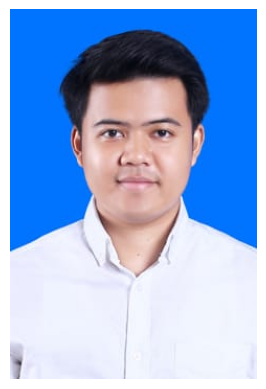

In [ ]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis('off')
plt.show()

In [ ]:
# import cv2
# import matplotlib.pyplot as plt

# Read image
image = cv2.imread('/content/Dito_BG Biru.jpg')

# Resize
resize = cv2.resize(image, (500, 300))

# Crop
crop = image[100:400, 200:600]

# Grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Threshold
_, threshold = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# Blur
blur = cv2.GaussianBlur(image, (5, 5), 0)

# Edge Detection
edge = cv2.Canny(gray, 100, 200)

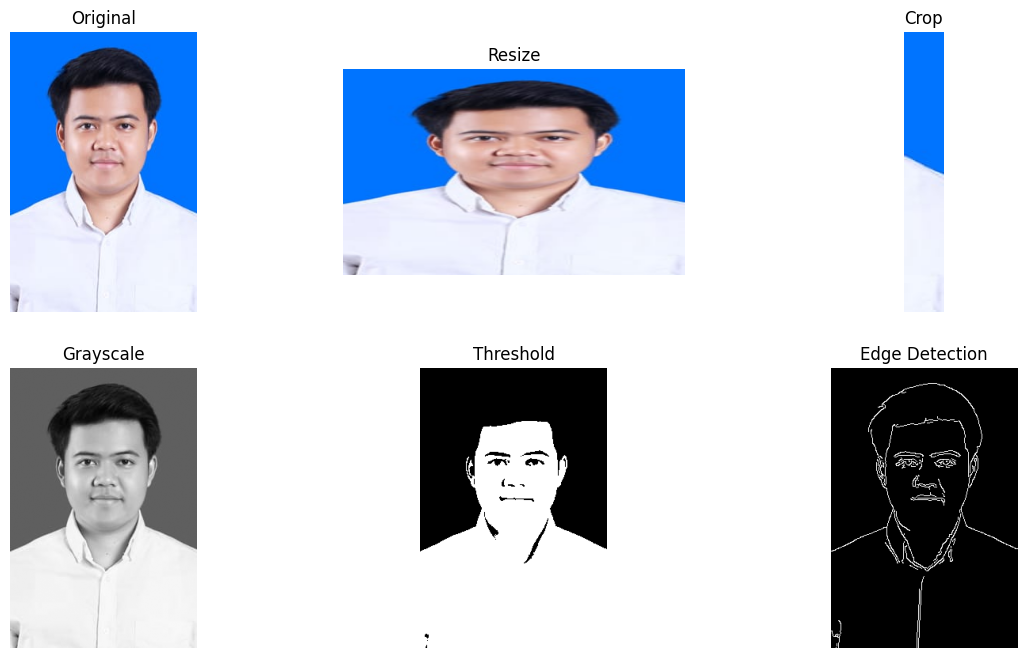

In [ ]:
# Display results

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(cv2.cvtColor(resize, cv2.COLOR_BGR2RGB))
plt.title('Resize')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.title('Crop')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(threshold, cmap='gray')
plt.title('Threshold')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(edge, cmap='gray')
plt.title('Edge Detection')
plt.axis('off')

plt.show()

**Face Detection**

In [ ]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

In [ ]:
def take_photo():
    display(Javascript('''
    async function takePhoto() {
        const video = document.createElement('video');
        document.body.appendChild(video);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => setTimeout(resolve, 1000));

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getVideoTracks()[0].stop();
        video.remove();

        return canvas.toDataURL('image/jpeg');
    }
    '''))

    data = eval_js('takePhoto()')
    return b64decode(data.split(',')[1])

In [ ]:
photo = take_photo()

with open('/content/webcam.jpg', 'wb') as f:
    f.write(photo)

image = cv2.imread('/content/webcam.jpg')

<IPython.core.display.Javascript object>

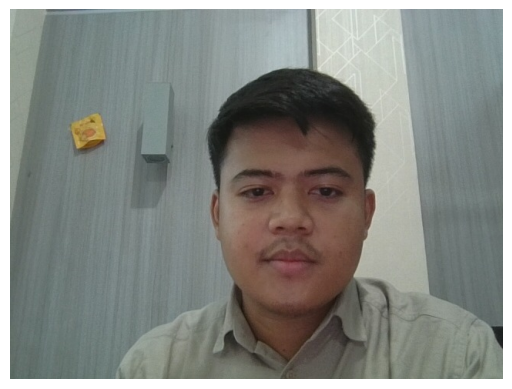

In [ ]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis('off')
plt.show()

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import matplotlib.pyplot as plt

def take_photo():
    js = Javascript('''
        async function takePhoto() {
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = 'Take Photo';
            div.appendChild(capture);

            const video = document.createElement('video');
            video.style.display = 'block';

            const stream = await navigator.mediaDevices.getUserMedia({
                video: true
            });

            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            await new Promise((resolve) =>
                capture.onclick = resolve
            );

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);

            stream.getTracks().forEach(track => track.stop());
            div.remove();

            return canvas.toDataURL('image/jpeg');
        }
        takePhoto();
    ''')
    display(js)
    data = eval_js('takePhoto()')
    return b64decode(data.split(',')[1])

In [ ]:
photo = take_photo()

with open('/content/webcam.jpg', 'wb') as f:
    f.write(photo)

image = cv2.imread('/content/webcam.jpg')

if image is not None:
    print("Foto berhasil diambil.")
    print("Ukuran gambar:", image.shape)
else:
    print("Gagal membaca gambar.")

<IPython.core.display.Javascript object>

Foto berhasil diambil.
Ukuran gambar: (480, 640, 3)


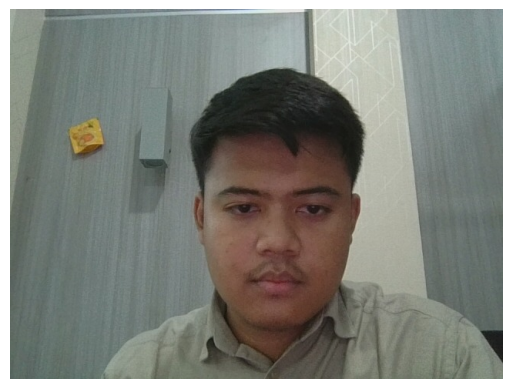

In [ ]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis('off')
plt.show()

In [ ]:
import cv2

print("Versi:", cv2.__version__)
print("Lokasi:", cv2.__file__)
print("CascadeClassifier tersedia:",
      hasattr(cv2, "CascadeClassifier"))

Versi: 5.0.0
Lokasi: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
CascadeClassifier tersedia: True


In [ ]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install opencv-contrib-python

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 9.3 MB/s eta 0:00:00


In [ ]:
import cv2
import urllib.request
import os

cascade_path = '/content/haarcascade_frontalface_default.xml'

# Unduh file jika belum ada
if not os.path.exists(cascade_path):
    url = (
        'https://raw.githubusercontent.com/opencv/opencv/'
        '4.x/data/haarcascades/'
        'haarcascade_frontalface_default.xml'
    )
    urllib.request.urlretrieve(url, cascade_path)

# Inisialisasi Cascade Classifier dengan aman
face_cascade = cv2.CascadeClassifier(cascade_path)

# Jika gagal memuat file lokal, gunakan fallback internal bawaan OpenCV
if face_cascade.empty():
    fallback_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
    face_cascade = cv2.CascadeClassifier(fallback_path)

if face_cascade.empty():
    print("Haar Cascade gagal dimuat!")
else:
    print("Haar Cascade berhasil dimuat!")

Haar Cascade berhasil dimuat!


In [ ]:

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Jumlah wajah terdeteksi:", len(faces))


Jumlah wajah terdeteksi: 1


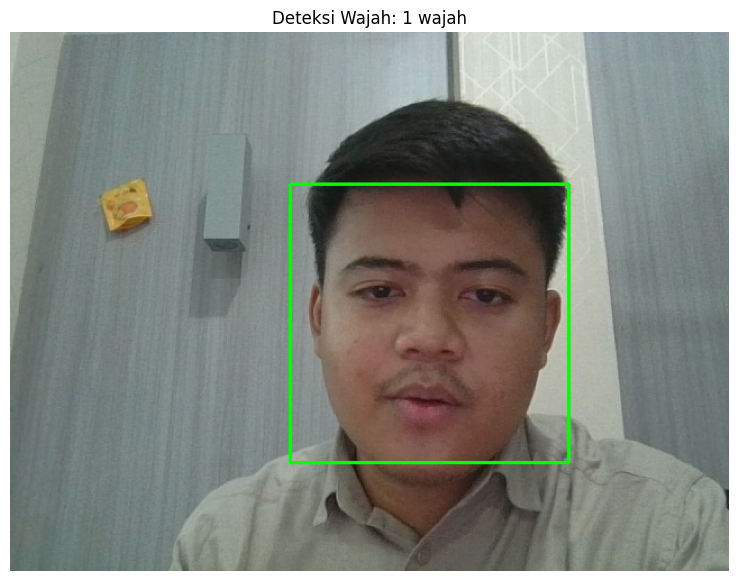

Jumlah wajah terdeteksi: 1


In [ ]:

import cv2
import matplotlib.pyplot as plt

# Salin gambar agar gambar asli tidak berubah
result = image.copy()

# Gambar kotak pada setiap wajah
for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

# Konversi BGR ke RGB
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

# Tampilkan hasil deteksi
plt.figure(figsize=(10, 7))
plt.imshow(result_rgb)
plt.title(f"Deteksi Wajah: {len(faces)} wajah")
plt.axis("off")
plt.show()

print("Jumlah wajah terdeteksi:", len(faces))


**LIVE webcam + face detection**

In [ ]:
from IPython.display import display, Javascript

display(Javascript("""
(async () => {

  // Load OpenCV.js
  if (!window.cv) {
    await new Promise((resolve, reject) => {
      const script = document.createElement('script');
      script.src = 'https://docs.opencv.org/4.x/opencv.js';
      script.onload = resolve;
      script.onerror = reject;
      document.head.appendChild(script);
    });
  }

  while (!window.cv || !window.cv.Mat) {
    await new Promise(resolve => setTimeout(resolve, 100));
  }

  // Create video
  const video = document.createElement('video');
  video.autoplay = true;
  video.playsInline = true;
  video.style.width = '640px';

  // Create canvas
  const canvas = document.createElement('canvas');
  canvas.width = 640;
  canvas.height = 480;
  canvas.style.width = '640px';

  // Create button
  const button = document.createElement('button');
  button.innerText = 'Stop Webcam';

  document.body.appendChild(video);
  document.body.appendChild(canvas);
  document.body.appendChild(button);

  // Open webcam
  const stream = await navigator.mediaDevices.getUserMedia({
    video: true
  });

  video.srcObject = stream;

  // Load Haar Cascade
  const response = await fetch(
    'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml'
  );

  const xml = await response.text();

  cv.FS_createDataFile(
    '/',
    'haarcascade_frontalface_default.xml',
    xml,
    true,
    false,
    false
  );

  const classifier = new cv.CascadeClassifier();
  classifier.load('haarcascade_frontalface_default.xml');

  const ctx = canvas.getContext('2d');

  let running = true;

  button.onclick = () => {
    running = false;
    stream.getTracks().forEach(track => track.stop());
    video.remove();
    canvas.remove();
    button.remove();
  };

  // Face detection loop
  function detectFace() {

    if (!running) return;

    ctx.drawImage(video, 0, 0, 640, 480);

    let src = cv.imread(canvas);
    let gray = new cv.Mat();

    cv.cvtColor(src, gray, cv.COLOR_RGBA2GRAY);

    let faces = new cv.RectVector();
    let faceSize = new cv.Size(30, 30);

    classifier.detectMultiScale(
      gray,
      faces,
      1.1,
      5,
      0,
      faceSize
    );

    // Draw bounding boxes
    for (let i = 0; i < faces.size(); i++) {

      let face = faces.get(i);

      let point1 = new cv.Point(face.x, face.y);
      let point2 = new cv.Point(
        face.x + face.width,
        face.y + face.height
      );

      cv.rectangle(
        src,
        point1,
        point2,
        [0, 255, 0, 255],
        3
      );
    }

    cv.imshow(canvas, src);

    src.delete();
    gray.delete();
    faces.delete();

    requestAnimationFrame(detectFace);
  }

  detectFace();

})();
"""))

<IPython.core.display.Javascript object>

Face Recognition

In [ ]:
!pip install opencv-contrib-python -q

In [ ]:
import cv2
import os
import numpy as np

dataset_path = '/content/Dito'

faces = []
labels = []

for filename in os.listdir(dataset_path):

    path = os.path.join(dataset_path, filename)

    image = cv2.imread(path)

    if image is None:
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces.append(gray)
    labels.append(0)

print("Jumlah data:", len(faces))

Jumlah data: 15


In [ ]:
recognizer = cv2.face.LBPHFaceRecognizer_create()

In [ ]:
recognizer.train(faces, np.array(labels))

print("Training selesai!")

Training selesai!


In [ ]:
recognizer.write('/content/dito_model.yml')

In [ ]:
image = cv2.imread('/content/dimas.jpg')

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [ ]:
import os

# Load the local cascade file directly
cascade_path = 'haarcascade_frontalface_default.xml'

if not os.path.exists(cascade_path):
    # Fallback to cv2.data.haarcascades if local file is missing
    cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'

face_cascade = cv2.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise IOError(f"Could not load cascade classifier from: {cascade_path}")

faces_detected = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5
)

In [ ]:
threshold = 30

for (x, y, w, h) in faces_detected:

    face = gray[y:y+h, x:x+w]

    label, confidence = recognizer.predict(face)

    if label == 0 and confidence < threshold:
        name = "Dito"
    else:
        name = "Dimas"

    cv2.rectangle(
        image,
        (x, y),
        (x+w, y+h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        image,
        f"{name} {confidence:.1f}",
        (x, y-10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

In [ ]:
import matplotlib.pyplot as plt

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis('on')
plt.show()

NameError: name 'cv2' is not defined

In [ ]:
image = cv2.imread('/content/test3.jpg')

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [ ]:
# Deteksi wajah
faces_detected = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=8,
    minSize=(100, 100)
)

# Ambil hanya 1 wajah terbesar
if len(faces_detected) > 0:

    x, y, w, h = max(
        faces_detected,
        key=lambda face: face[2] * face[3]
    )

    face = gray[y:y+h, x:x+w]

    label, confidence = recognizer.predict(face)

    threshold = 70

    if label == 0 and confidence < threshold:
        name = "Dito"
    else:
        name = "Orang lain"

    cv2.rectangle(
        image,
        (x, y),
        (x+w, y+h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        image,
        f"{name} {confidence:.1f}",
        (x, y-10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

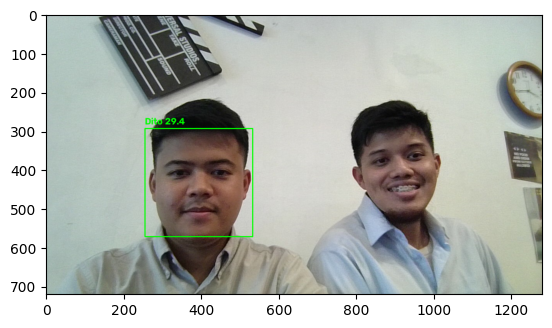

In [ ]:
import matplotlib.pyplot as plt

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis('on')
plt.show()